# 700-sign frozen-GRU classification-layer experiment

The selected epoch-213 2Г—256 GRU backbone is frozen. Compare (1) its original jointly trained linear classifier, (2) a new linear classifier fitted on frozen features, and (3) a new hidden linear layer with ReLU and dropout followed by a linear 700-class output. Both newly fitted heads use identical features, splits, optimizer and selection rules; they differ in architecture. This makes a controlled classifier comparison, while the original head is a historical reference trained jointly with the GRU.

The 700-class test split has already been used during earlier full-vocabulary experiments. It is read only after the new heads have been selected on validation. Its results are not a fresh blind evaluation. No webcam is opened and the backbone is not retrained.

In [1]:
from pathlib import Path
import os,sys,json,time,random,hashlib,copy
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader,Dataset,TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence,pad_packed_sequence
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support,confusion_matrix
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/sign_language').is_dir());sys.path.insert(0,str(ROOT/'src'))
from sign_language.temporal_augmentation import TemporalCollator
from sign_language.trajectory_geometry import trajectory_batch,FEATURES
from sign_language.five_sign_pilot import sha256
PARENT=ROOT/'data/training/asl-gru-128-v1';RUN=ROOT/'models/asl-700-sign-gru-comparison-v1'
BACKBONE=RUN/'gru_2x256/best-backbone.pt';OUT=ROOT/'models/asl-700-sign-gru-2x256-two-layer-head-v1'
assert not OUT.exists(),f'{OUT} exists; select a new experiment directory'
manifest=json.loads((PARENT/'manifest.json').read_text());labels=json.loads((RUN/'labels.json').read_text());names=[k for k,v in sorted(labels.items(),key=lambda kv:kv[1])]
assert len(names)==700 and sorted(labels.values())==list(range(700))
assert torch.cuda.is_available();torch.set_num_threads(2);torch.backends.cudnn.enabled=False;torch.backends.cudnn.benchmark=False
baseline_hash=sha256(BACKBONE);state=torch.load(BACKBONE,map_location='cpu',weights_only=True)
assert state['epoch']==213 and state['config']['model']['layers']==2 and state['config']['model']['hidden_size']==256
assert state['config']['parent_cache_id']==manifest['cache_id'] and state['config']['preprocessing']['max_frames']==83 and state['labels']==labels
print('Backbone SHA256',baseline_hash,'epoch',state['epoch'],'GPU',torch.cuda.get_device_name())

Backbone SHA256 d0dc612ca51502193ad137c53681fc7c55d5dd1d9dd2c52f27886581a598b0ba epoch 213 GPU NVIDIA GeForce RTX 4060


## Reconstruct the data and frozen model

These definitions reproduce the 700-sign experiment's existing cache integrity checks and 83-frame sampling. Geometry is calculated from the actual sampled sequence and standardized with the original training-only statistics.

In [2]:
from sign_language.expanded_pilot import digest_chunk
class SelectedDataset(Dataset):
    def __init__(self,split,index):
        self.split=split;self.index=index;self.rows=[i for i,r in enumerate(index) if r['gloss'] in labels]
        self.arrays=[np.load(PARENT/f'{split}-{n}.npy',mmap_mode='r') for n in ('features','lengths','targets')]
        assert all(len(a)==len(index) for a in self.arrays)
        needed=set(self.rows)
        for marker in sorted(PARENT.glob(f'{split}-*.prepared.json')):
            record=json.loads(marker.read_text());start,count=record['start'],record['count'];covered=needed.intersection(range(start,start+count))
            if covered:
                assert record['cache_id']==manifest['cache_id'] and digest_chunk(self.arrays,start,count)==record['sha256'],marker
                needed.difference_update(covered)
        assert not needed
        assert all(int(self.arrays[2][i])==manifest['labels'][index[i]['gloss']] for i in self.rows)
    def __len__(self):return len(self.rows)
    def __getitem__(self,j):
        i=self.rows[j];return torch.from_numpy(np.array(self.arrays[0][i],dtype=np.float32)),int(self.arrays[1][i]),labels[self.index[i]['gloss']]

In [3]:
class DeepTrajectoryGRU(nn.Module):
    def __init__(self, input_size=254, hidden_size=256, layers=2, classes=700, dropout=.5):
        super().__init__()
        self.gru=nn.GRU(input_size,hidden_size,num_layers=layers,batch_first=True,dropout=dropout)
        self.dropout=nn.Dropout(dropout)
        self.classifier=nn.Linear(hidden_size+len(FEATURES),classes)
        for name in ('median','mean','scale'):
            self.register_buffer('geometry_'+name,torch.ones(len(FEATURES)) if name=='scale' else torch.zeros(len(FEATURES)))
    def set_statistics(self,stats):
        for name in ('median','mean','scale'):
            value=torch.tensor(stats[name],dtype=torch.float32,device=self.geometry_mean.device)
            assert value.shape==(len(FEATURES),) and torch.isfinite(value).all()
            if name=='scale': assert (value>0).all()
            getattr(self,'geometry_'+name).copy_(value)
    def encode(self,frames,lengths):
        packed=pack_padded_sequence(frames,lengths.cpu(),batch_first=True,enforce_sorted=False)
        packed,_=self.gru(packed)
        values,actual=pad_packed_sequence(packed,batch_first=True)
        mask=(torch.arange(values.shape[1],device=values.device)[None,:]<actual.to(values.device)[:,None]).unsqueeze(-1)
        return (values*mask).sum(1)/actual.to(values.device).clamp_min(1)[:,None]
    def standardized_geometry(self,geometry):
        return (torch.where(torch.isnan(geometry),self.geometry_median,geometry)-self.geometry_mean)/self.geometry_scale
    def forward(self,frames,lengths):
        pooled=self.dropout(self.encode(frames,lengths))
        geometry=torch.as_tensor(trajectory_batch(frames,lengths),device=frames.device,dtype=torch.float32)
        values=torch.cat((pooled,self.standardized_geometry(geometry)),dim=1)
        return self.classifier(values)

In [4]:
MAX_FRAMES=83
class FrameLimitCollator:
    def __init__(self,augment=False): self.temporal=TemporalCollator(enabled=augment)
    def __call__(self,samples):
        frames,lengths,targets=self.temporal(samples)
        limited=torch.zeros((len(frames),MAX_FRAMES,frames.shape[2]),dtype=frames.dtype)
        lengths_out=[]
        for i,length in enumerate(lengths.tolist()):
            take=min(int(length),MAX_FRAMES)
            if int(length)>MAX_FRAMES:
                indices=torch.linspace(0,int(length)-1,MAX_FRAMES).round().long()
                limited[i,:take]=frames[i,indices]
            else: limited[i,:take]=frames[i,:take]
            lengths_out.append(take)
        return limited,torch.tensor(lengths_out,dtype=torch.long),targets

In [5]:
backbone=DeepTrajectoryGRU(**state['config']['model']).cuda().eval();backbone.load_state_dict(state['model'],strict=True);backbone.requires_grad_(False)
indexes={s:json.loads((PARENT/f'{s}-index.json').read_text()) for s in ('train','val')}
train_data=SelectedDataset('train',indexes['train']);val_data=SelectedDataset('val',indexes['val'])
people={s:{indexes[s][i]['participant_id'] for i in ds.rows} for s,ds in [('train',train_data),('val',val_data)]};assert not people['train']&people['val']
OUT.mkdir(parents=True,exist_ok=False)
(OUT/'status.json').write_text(json.dumps({'status':'extracting_frozen_features'},indent=2))
def make_loader(ds):return DataLoader(ds,batch_size=16,shuffle=False,num_workers=0,collate_fn=FrameLimitCollator())
def extract(loader):
    features=[];targets=[]
    with torch.inference_mode():
        for batch,(frames,lengths,y) in enumerate(loader,1):
            frames=frames.cuda()
            with torch.autocast('cuda',dtype=torch.float16): hidden=backbone.encode(frames,lengths).float()
            geometry=torch.as_tensor(trajectory_batch(frames,lengths),device='cuda',dtype=torch.float32)
            features.append(torch.cat((hidden,backbone.standardized_geometry(geometry)),1).cpu());targets.append(y.long())
            if batch%150==0:print('frozen features',batch,'/',len(loader),flush=True)
    return torch.cat(features),torch.cat(targets)
train_x,train_y=extract(make_loader(train_data));val_x,val_y=extract(make_loader(val_data))
assert train_x.shape==(11355,279) and val_x.shape==(2413,279)
assert torch.isfinite(train_x).all() and torch.isfinite(val_x).all()
print('train/validation features',train_x.shape,val_x.shape)

frozen features 150 / 710
frozen features 300 / 710
frozen features 450 / 710
frozen features 600 / 710
frozen features 150 / 151
train/validation features torch.Size([11355, 279]) torch.Size([2413, 279])


## Classifier definitions and training

Each head receives 256 pooled GRU features plus 23 geometry features. The additional layer has 256 hidden units, ReLU and dropout 0.3. Both heads use AdamW (learning rate 0.001, weight decay 0.001), cross-entropy, batch size 256, up to 100 epochs and validation-loss patience 12. Train features are unaugmented and use a frozen backbone. Save only the best head from each experiment.

In [6]:
class LinearHead(nn.Module):
    def __init__(self):super().__init__();self.output=nn.Linear(279,700)
    def forward(self,x):return self.output(x)
class TwoLayerHead(nn.Module):
    def __init__(self):super().__init__();self.hidden=nn.Linear(279,256);self.activation=nn.ReLU();self.dropout=nn.Dropout(.3);self.output=nn.Linear(256,700)
    def forward(self,x):return self.output(self.dropout(self.activation(self.hidden(x))))

def head_epoch(head,loader,optimizer=None):
    training=optimizer is not None;head.train(training);loss_sum=0.;correct=total=0
    with torch.set_grad_enabled(training):
        for x,y in loader:
            x=x.cuda();y=y.cuda()
            if training:optimizer.zero_grad(set_to_none=True)
            logits=head(x);loss=nn.functional.cross_entropy(logits,y)
            if not torch.isfinite(loss):raise FloatingPointError('Non-finite head loss')
            if training:loss.backward();optimizer.step()
            total+=len(y);loss_sum+=loss.item()*len(y);correct+=(logits.argmax(1)==y).sum().item()
    return {'samples':total,'loss':loss_sum/total,'top1':correct/total}

def train_head(tag,cls):
    random.seed(42);np.random.seed(42);torch.manual_seed(42);torch.cuda.manual_seed_all(42)
    head=cls().cuda();optimizer=torch.optim.AdamW(head.parameters(),lr=.001,weight_decay=.001)
    generator=torch.Generator().manual_seed(42)
    train_loader=DataLoader(TensorDataset(train_x,train_y),batch_size=256,shuffle=True,generator=generator)
    val_loader=DataLoader(TensorDataset(val_x,val_y),batch_size=256,shuffle=False)
    history=[];best=float('inf');best_state=None;best_epoch=0;stale=0
    for epoch in range(1,101):
        train=head_epoch(head,train_loader,optimizer);val=head_epoch(head,val_loader)
        history.append({'epoch':epoch,'train':train,'val':val})
        if val['loss']<best-.0001:best=val['loss'];best_epoch=epoch;best_state={k:v.detach().cpu().clone() for k,v in head.state_dict().items()};stale=0
        else:stale+=1
        if epoch%5==0 or epoch==1:print(f"{tag} {epoch:03}: train {train['top1']:.1%}, val {val['top1']:.1%}, loss {val['loss']:.4f}",flush=True)
        if stale>=12:break
    head.load_state_dict(best_state);head.eval()
    return head,history,best_epoch
heads={};histories={};selected={}
for tag,cls in [('linear',LinearHead),('two_layer',TwoLayerHead)]:
    heads[tag],histories[tag],selected[tag]=train_head(tag,cls)
    torch.save({'head':heads[tag].state_dict(),'architecture':tag,'selected_epoch':selected[tag],'backbone_sha256':baseline_hash,'labels':labels,'hidden_units':256 if tag=='two_layer' else None,'dropout':.3 if tag=='two_layer' else None},OUT/(tag+'.pt'))
    (OUT/(tag+'-history.json')).write_text(json.dumps(histories[tag],indent=2))
(OUT/'status.json').write_text(json.dumps({'status':'heads_selected','epochs':selected},indent=2))
assert sha256(BACKBONE)==baseline_hash
print('Selected epochs',selected)

linear 001: train 12.5%, val 35.5%, loss 4.8320
linear 005: train 77.2%, val 68.3%, loss 2.0513
linear 010: train 85.7%, val 71.2%, loss 1.4606
linear 015: train 90.3%, val 71.9%, loss 1.2907
linear 020: train 93.4%, val 71.9%, loss 1.2209
linear 025: train 96.1%, val 72.2%, loss 1.1830
linear 030: train 97.7%, val 71.8%, loss 1.1634
linear 035: train 98.7%, val 71.9%, loss 1.1516
linear 040: train 99.3%, val 72.1%, loss 1.1437
linear 045: train 99.7%, val 71.8%, loss 1.1409
linear 050: train 99.9%, val 71.6%, loss 1.1400
linear 055: train 99.9%, val 72.0%, loss 1.1411
linear 060: train 99.9%, val 72.0%, loss 1.1406
linear 065: train 100.0%, val 72.0%, loss 1.1444
two_layer 001: train 6.0%, val 23.7%, loss 4.9847
two_layer 005: train 65.8%, val 64.0%, loss 1.5010
two_layer 010: train 79.0%, val 68.3%, loss 1.2855
two_layer 015: train 85.2%, val 69.2%, loss 1.2458
two_layer 020: train 89.8%, val 69.2%, loss 1.2730
two_layer 025: train 92.3%, val 70.0%, loss 1.2847
Selected epochs {'line

## Final metrics on official splits

Validation chooses the head epoch. The previously inspected test split is opened only now. Accuracy, cross-entropy, top-5 accuracy, macro precision/recall/F1, weighted F1 and per-class scores are recorded.

In [7]:
def report_metrics(logits,y):
    pred=logits.argmax(1);p,r,f,s=precision_recall_fscore_support(y.numpy(),pred.numpy(),labels=np.arange(700),zero_division=0)
    return {'samples':len(y),'correct':int((pred==y).sum()),'top1':float((pred==y).float().mean()),'top5':float((logits.topk(5,1).indices==y[:,None]).any(1).float().mean()),'loss':float(nn.functional.cross_entropy(logits,y).item()),'macro_precision':float(p.mean()),'macro_recall':float(r.mean()),'macro_f1':float(f.mean()),'weighted_f1':float(np.average(f,weights=s)), 'per_class':{name:{'support':int(s[i]),'precision':float(p[i]),'recall':float(r[i]),'f1':float(f[i])} for i,name in enumerate(names)}}

test_index=json.loads((PARENT/'test-index.json').read_text());test_data=SelectedDataset('test',test_index)
test_people={test_index[i]['participant_id'] for i in test_data.rows};assert not test_people&(people['train']|people['val'])
test_x,test_y=extract(make_loader(test_data))
results={}
for split,(x,y) in {'train':(train_x,train_y),'val':(val_x,val_y),'test':(test_x,test_y)}.items():
    with torch.inference_mode():
        original=nn.functional.linear(x,backbone.classifier.weight.cpu(),backbone.classifier.bias.cpu())
        outputs={'original_linear':original,**{tag:head(x.cuda()).cpu() for tag,head in heads.items()}}
    for tag,logits in outputs.items():results.setdefault(tag,{})[split]=report_metrics(logits,y)
    print(split,[(tag,round(results[tag][split]['top1']*100,2),round(results[tag][split]['macro_f1']*100,2)) for tag in outputs])
assert sha256(BACKBONE)==baseline_hash
report={'status':'complete','baseline_checkpoint_sha256':baseline_hash,'selected_epochs':selected,'models':results,'protocol':{'frozen_backbone':True,'max_frames':83,'test_previously_seen':True,'train_features_augmented':False,'optimizer':'AdamW lr=0.001 weight_decay=0.001','batch_size':256,'early_stopping_patience':12}}
(OUT/'report.json').write_text(json.dumps(report,indent=2));(OUT/'status.json').write_text(json.dumps({'status':'complete','epochs':selected},indent=2))

frozen features 150 / 516
frozen features 300 / 516
frozen features 450 / 516
train [('original_linear', 86.28, 86.02), ('linear', 99.91, 99.91), ('two_layer', 93.85, 93.82)]
val [('original_linear', 71.03, 69.85), ('linear', 71.82, 71.23), ('two_layer', 69.17, 68.12)]
test [('original_linear', 60.63, 59.84), ('linear', 60.99, 60.67), ('two_layer', 58.73, 58.41)]


## Learning curves and comparison

original_linear selected epoch backbone 213
train {'top1': 0.8628, 'top5': 0.9695, 'loss': 0.5516, 'macro_precision': 0.8811, 'macro_recall': 0.8635, 'macro_f1': 0.8602, 'weighted_f1': 0.8601} n= 11355
val {'top1': 0.7103, 'top5': 0.9196, 'loss': 1.1559, 'macro_precision': 0.7439, 'macro_recall': 0.7164, 'macro_f1': 0.6985, 'weighted_f1': 0.6956} n= 2413
test {'top1': 0.6063, 'top5': 0.8272, 'loss': 1.7828, 'macro_precision': 0.6497, 'macro_recall': 0.6068, 'macro_f1': 0.5984, 'weighted_f1': 0.5987} n= 8250
linear selected epoch 53
train {'top1': 0.9991, 'top5': 1.0, 'loss': 0.1031, 'macro_precision': 0.9992, 'macro_recall': 0.9992, 'macro_f1': 0.9991, 'weighted_f1': 0.9991} n= 11355
val {'top1': 0.7182, 'top5': 0.9155, 'loss': 1.138, 'macro_precision': 0.7501, 'macro_recall': 0.725, 'macro_f1': 0.7123, 'weighted_f1': 0.7097} n= 2413
test {'top1': 0.6099, 'top5': 0.8219, 'loss': 1.7492, 'macro_precision': 0.6303, 'macro_recall': 0.6101, 'macro_f1': 0.6067, 'weighted_f1': 0.6073} n= 825

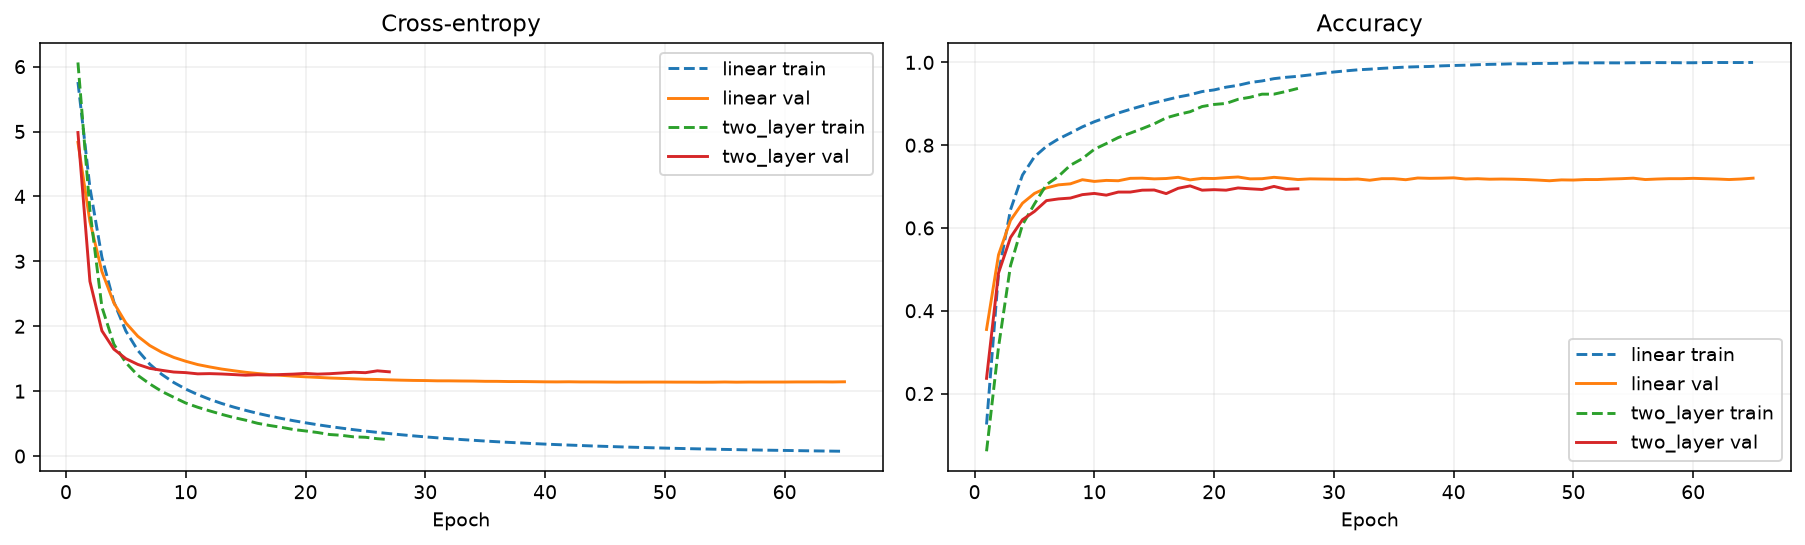

In [8]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
for tag,history in histories.items():
    epochs=[r['epoch'] for r in history]
    for split,style in [('train','--'),('val','-')]:
        axes[0].plot(epochs,[r[split]['loss'] for r in history],linestyle=style,label=tag+' '+split)
        axes[1].plot(epochs,[r[split]['top1'] for r in history],linestyle=style,label=tag+' '+split)
for ax,title in zip(axes,['Cross-entropy','Accuracy']):ax.set(title=title,xlabel='Epoch');ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()
for tag,metrics_by_split in results.items():
    print(tag,'selected epoch',selected.get(tag,'backbone 213'))
    for split,m in metrics_by_split.items():print(split,{k:round(m[k],4) for k in ('top1','top5','loss','macro_precision','macro_recall','macro_f1','weighted_f1')},'n=',m['samples'])

## Export the combined two-layer model

This bundle contains both the frozen recurrent backbone and the new head, plus labels and preprocessing configuration. The webcam integration remains a separate step.

In [9]:
class GRUWithTwoLayerHead(nn.Module):
    def __init__(self,backbone,head):
        super().__init__();self.backbone=backbone;self.head=head
    def forward(self,frames,lengths):
        with torch.autocast(device_type=frames.device.type,dtype=torch.float16,enabled=frames.device.type=='cuda'):
            hidden=self.backbone.encode(frames,lengths).float()
        geometry=torch.as_tensor(trajectory_batch(frames,lengths),device=frames.device,dtype=torch.float32)
        inputs=torch.cat((hidden,self.backbone.standardized_geometry(geometry)),1)
        return self.head(inputs)

combined=GRUWithTwoLayerHead(backbone,heads['two_layer']).eval()
bundle={'schema':'700-sign-frozen-gru-two-layer-head-v1','backbone':{k:v.detach().cpu() for k,v in backbone.state_dict().items()},'head':{k:v.detach().cpu() for k,v in heads['two_layer'].state_dict().items()},'backbone_config':state['config'],'backbone_epoch':state['epoch'],'backbone_sha256':baseline_hash,'head_selected_epoch':selected['two_layer'],'labels':labels,'classifier':{'input_size':279,'hidden_size':256,'output_size':700,'activation':'ReLU','dropout':0.3},'notebook':'notebooks/06_700_sign_classifier_comparison.ipynb'}
torch.save(bundle,OUT/'model.pt')
print('Combined model saved:',OUT/'model.pt')

Combined model saved: E:\minor_major_proj\models\asl-700-sign-gru-2x256-two-layer-head-v1\model.pt
